In [1]:
from google.colab import files
files.upload()
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

Saving kaggle.json to kaggle.json


In [2]:
import kagglehub
import shutil

# Download latest version
path = kagglehub.dataset_download("patelris/crop-yield-prediction-dataset")
destination = "/content/crop-yield-prediction-dataset"
shutil.copytree(path, destination, dirs_exist_ok=True)

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'crop-yield-prediction-dataset' dataset.
Path to dataset files: /kaggle/input/crop-yield-prediction-dataset


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


data = pd.read_csv("/content/crop-yield-prediction-dataset/yield_df.csv")
df = pd.DataFrame(data)
df.head()

,Unnamed: 0,Area,Item,Year,hg/ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
0,0,Albania,Maize,1990,36613,1485.0,121.0,16.37
1,1,Albania,Potatoes,1990,66667,1485.0,121.0,16.37
2,2,Albania,"Rice, paddy",1990,23333,1485.0,121.0,16.37
3,3,Albania,Sorghum,1990,12500,1485.0,121.0,16.37
4,4,Albania,Soybeans,1990,7000,1485.0,121.0,16.37


In [ ]:
import torch
dev="cuda" if torch.cuda.is_available() else "cpu"
x=torch.tensor(x,dtype=torch.float32,device=dev)
y=torch.tensor(y,dtype=torch.float32,device=dev)
w=torch.zeros(1,device=dev,requires_grad=True)
b=torch.zeros(1,device=dev,requires_grad=True)
loss=((w*x+b-y)**2).mean(); loss.backward()

In [4]:
yield_crops = df['hg/ha_yield'].to_numpy()
rainfall = df['average_rain_fall_mm_per_year'].to_numpy()

idx=np.random.default_rng(0).permutation(len(yield_crops))
cut=int(0.8*len(yield_crops)); tr,te=idx[:cut],idx[cut:]

In [5]:
x = rainfall[tr]
y = yield_crops[tr]

#standardise training data
x_mean, x_std = x.mean(), x.std()
y_mean, y_std = y.mean(), y.std()

x = (x - x_mean) / x_std
y = (y - y_mean) / y_std


In [6]:
import torch
dev="cuda" if torch.cuda.is_available() else "cpu"
x=torch.tensor(x,dtype=torch.float32,device=dev)
y=torch.tensor(y,dtype=torch.float32,device=dev)
w=torch.zeros(1,device=dev,requires_grad=True)
b=torch.zeros(1,device=dev,requires_grad=True)


Epoch 100: Weight=-0.00238806, Bias=0.00000000, Loss=0.99999261
Epoch 200: Weight=-0.00270476, Bias=0.00000000, Loss=0.99999249
Epoch 300: Weight=-0.00274676, Bias=-0.00000000, Loss=0.99999243
Epoch 400: Weight=-0.00275233, Bias=-0.00000000, Loss=0.99999243
Epoch 500: Weight=-0.00275307, Bias=0.00000000, Loss=0.99999243


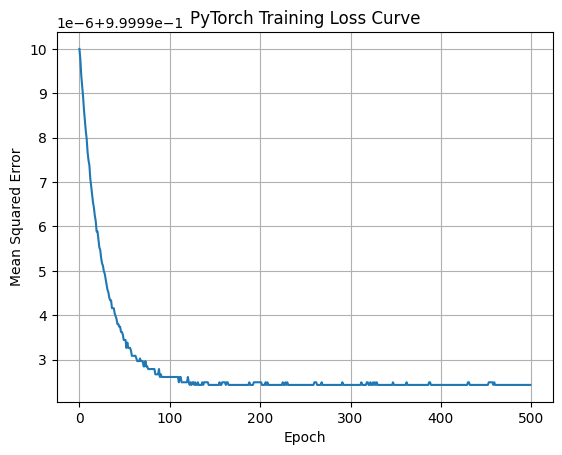

Weight: -0.0027530710212886333
Bias: 2.142041127806138e-10
Final Training MSE: 0.9999924302101135


In [7]:
lr = 0.01
optimizer = torch.optim.SGD([w, b], lr=lr)

loss_history = []

#train the model
for e in range(500):
    y_pred = w*x + b
    loss = ((y_pred - y)**2).mean()
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    loss_history.append(loss.item())
    if (e + 1) % 100 == 0:
        print(f"Epoch {e+1}: Weight={w.item():.8f}, Bias={b.item():.8f}, Loss={loss.item():.8f}")

#plot
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("PyTorch Training Loss Curve")
plt.grid(True)
plt.show()

#display final results
print("Weight:", w.item())
print("Bias:", b.item())
print("Final Training MSE:", loss_history[-1])